In [33]:
# %pip install seaborn
# %pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [102]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error



In [78]:
df = pd.read_parquet('../data/green_tripdata_2025-01.parquet')
df.describe()

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee
count,48326.000000,48326,48326,46490.000000,48326.000000,48326.000000,46490.000000,48326.000000,48326.000000,48326.000000,48326.000000,48326.000000,48326.000000,0.0,48326.000000,48326.000000,46490.000000,46483.000000,46490.00000,46490.000000
mean,1.870215,2025-01-17 04:19:01.965753,2025-01-17 04:38:59.277448,1.184771,94.094545,142.409014,1.278103,21.532410,16.762466,0.932324,0.602776,2.481859,0.177461,NaN,0.988346,22.634242,1.266423,1.038788,0.85306,0.053350
min,1.000000,2024-12-25 23:13:15,2024-12-25 23:13:17,1.000000,3.000000,1.000000,0.000000,0.000000,-113.000000,-5.000000,-0.500000,-0.900000,0.000000,NaN,-1.000000,-114.000000,1.000000,1.000000,-2.75000,0.000000
25%,2.000000,2025-01-09 14:00:31.500000,2025-01-09 14:26:33.500000,1.000000,74.000000,74.000000,1.000000,1.100000,9.300000,0.000000,0.500000,0.000000,0.000000,NaN,1.000000,13.705000,1.000000,1.000000,0.00000,0.000000
50%,2.000000,2025-01-16 19:46:55.500000,2025-01-16 20:01:19.500000,1.000000,75.000000,140.000000,1.000000,1.740000,13.500000,0.000000,0.500000,2.070000,0.000000,NaN,1.000000,18.750000,1.000000,1.000000,0.00000,0.000000
75%,2.000000,2025-01-24 17:47:35.500000,2025-01-24 18:03:52,1.000000,97.000000,230.000000,1.000000,2.940000,19.100000,2.500000,0.500000,3.690000,0.000000,NaN,1.000000,26.465000,2.000000,1.000000,2.75000,0.000000
max,2.000000,2025-02-05 18:46:24,2025-02-05 19:11:47,99.000000,265.000000,265.000000,9.000000,84731.570000,336.200000,7.500000,4.250000,252.050000,48.760000,NaN,1.000000,371.400000,5.000000,2.000000,2.75000,0.750000
std,0.336070,NaN,NaN,1.442502,54.968061,77.251550,0.937178,990.646907,13.308342,1.348587,0.357366,3.213612,1.192984,NaN,0.130402,15.435061,0.471842,0.193092,1.27190,0.192788


In [25]:
df.isnull().sum()

VendorID                     0
lpep_pickup_datetime         0
lpep_dropoff_datetime        0
store_and_fwd_flag        1836
RatecodeID                1836
PULocationID                 0
DOLocationID                 0
passenger_count           1836
trip_distance                0
fare_amount                  0
extra                        0
mta_tax                      0
tip_amount                   0
tolls_amount                 0
ehail_fee                48326
improvement_surcharge        0
total_amount                 0
payment_type              1836
trip_type                 1843
congestion_surcharge      1836
cbd_congestion_fee        1836
dtype: int64

In [26]:
df.duplicated().sum()

np.int64(0)

In [29]:
td = df.duration.iloc[0]
td.total_seconds()/60

14.183333333333334

In [31]:
# df = df[df.trip_type == 2]

In [32]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,duration
0,2,2025-01-01 00:03:01,2025-01-01 00:17:12,N,1.0,75,235,1.0,5.93,24.70,...,6.80,0.00,NaN,1.0,34.00,1.0,1.0,0.00,0.0,14.183333
1,2,2025-01-01 00:19:59,2025-01-01 00:25:52,N,1.0,166,75,1.0,1.32,8.60,...,0.00,0.00,NaN,1.0,11.10,2.0,1.0,0.00,0.0,5.883333
2,2,2025-01-01 00:05:29,2025-01-01 00:07:21,N,5.0,171,73,1.0,0.41,25.55,...,0.00,0.00,NaN,1.0,26.55,2.0,2.0,0.00,0.0,1.866667
3,2,2025-01-01 00:52:24,2025-01-01 01:07:52,N,1.0,74,223,1.0,4.12,21.20,...,6.13,6.94,NaN,1.0,36.77,1.0,1.0,0.00,0.0,15.466667
4,2,2025-01-01 00:25:05,2025-01-01 01:01:10,N,1.0,66,158,1.0,4.71,33.80,...,7.81,0.00,NaN,1.0,46.86,1.0,1.0,2.75,0.0,36.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48321,2,2025-01-31 19:36:00,2025-01-31 20:05:00,NaN,NaN,179,132,NaN,13.99,55.61,...,11.42,0.00,NaN,1.0,68.53,NaN,NaN,NaN,NaN,29.000000
48322,2,2025-01-31 20:33:00,2025-01-31 20:41:00,NaN,NaN,166,75,NaN,1.51,13.58,...,2.26,0.00,NaN,1.0,17.34,NaN,NaN,NaN,NaN,8.000000
48323,2,2025-01-31 21:09:00,2025-01-31 21:30:00,NaN,NaN,41,42,NaN,2.90,30.89,...,0.00,0.00,NaN,1.0,32.39,NaN,NaN,NaN,NaN,21.000000
48324,2,2025-01-31 22:22:00,2025-01-31 22:25:00,NaN,NaN,75,43,NaN,0.34,14.78,...,2.44,0.00,NaN,1.0,18.72,NaN,NaN,NaN,NaN,3.000000


In [33]:
df.duration.describe()

count    48326.000000
mean        19.955195
std         93.924039
min          0.000000
25%          7.200000
50%         11.250000
75%         16.983333
max       1439.650000
Name: duration, dtype: float64

In [34]:
df.duration.value_counts()

duration
0.050000     221
0.066667     180
6.000000     150
0.033333     124
0.083333     123
            ... 
64.000000      1
88.000000      1
59.000000      1
67.016667      1
67.000000      1
Name: count, Length: 3362, dtype: int64

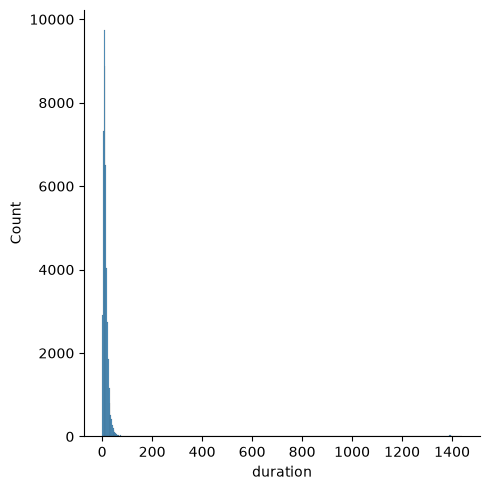

In [35]:
sns.displot(df.duration)

In [36]:
((df.duration >= 1) & (df.duration <= 60)).mean()

np.float64(0.9582212473616687)

<Axes: ylabel='duration'>

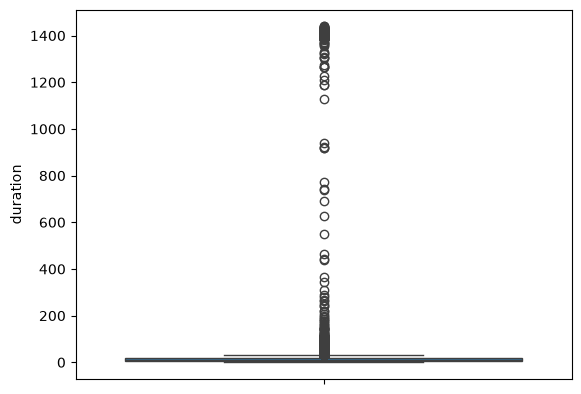

In [37]:
sns.boxplot(df.duration)

In [80]:
def read_df(filename):   
    df = pd.read_parquet(filename)
    df.lpep_dropoff_datetime = pd.to_datetime(df.lpep_dropoff_datetime)
    df.lpep_pickup_datetime = pd.to_datetime(df.lpep_pickup_datetime)
    df['duration'] = df.lpep_dropoff_datetime - df.lpep_pickup_datetime
    df.duration = df.duration.apply(lambda td: td.total_seconds()/60)
    categorical = ['PULocationID', 'DOLocationID']
    df[categorical] = df[categorical].astype(str)
    
    return df

In [82]:
df_train = read_df('../data/green_tripdata_2025-01.parquet')
df_val = read_df('../data/green_tripdata_2025-02.parquet')

In [83]:
len(df_train), len(df_val)

(48326, 46621)

In [38]:
numerical = ['trip_distance']

In [39]:
df[categorical].dtypes

PULocationID    int32
DOLocationID    int32
dtype: object

In [40]:
df[categorical] = df[categorical].astype(str)

In [43]:
df.dtypes

VendorID                          int32
lpep_pickup_datetime     datetime64[us]
lpep_dropoff_datetime    datetime64[us]
store_and_fwd_flag                  str
RatecodeID                      float64
PULocationID                        str
DOLocationID                        str
passenger_count                 float64
trip_distance                   float64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
ehail_fee                       float64
improvement_surcharge           float64
total_amount                    float64
payment_type                    float64
trip_type                       float64
congestion_surcharge            float64
cbd_congestion_fee              float64
duration                        float64
dtype: object

In [95]:
numerical = ['trip_distance']
dv = DictVectorizer()

train_dicts = df_train[categorical + numerical].to_dict(orient='records')

x_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
x_val = dv.transform(val_dicts)


In [96]:
target = 'duration'
y_train = df_train[target].values
y_val = df_val[target].values

In [101]:

lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred = lr.predict(x_val)

root_mean_squared_error(y_val, y_pred)


93.28543842493588

In [98]:
print(x_train.shape, x_val.shape)

(48326, 454) (46621, 454)


In [99]:

lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred = lr.predict(x_train)

root_mean_squared_error(y_train, y_pred)


93.25379865234169

In [105]:
import numpy as np

def to_int32(M):
    M = M.tocsr().copy()
    M.indices = M.indices.astype(np.int32)
    M.indptr = M.indptr.astype(np.int32)
    return M

x_train32 = to_int32(x_train)
x_val32 = to_int32(x_val)

lr = Lasso(alpha=0.01)
lr.fit(x_train32, y_train)
y_pred = lr.predict(x_val32)

root_mean_squared_error(y_val, y_pred)

93.24381797388696

In [ ]:
target = 'duration'
y_train = df[target].values

In [61]:
y_pred = lr.predict(x_train)

/tmp/ipykernel_2009/1505421196.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred, label='prediction')
/tmp/ipykernel_2009/1505421196.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_train, label='actual')


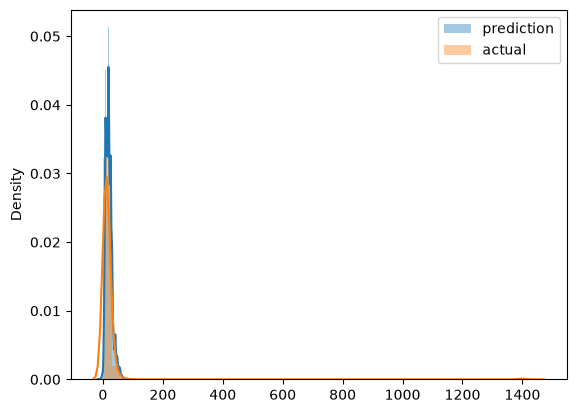

In [65]:
sns.distplot(y_pred, label='prediction')
sns.distplot(y_train, label='actual')
plt.legend()

In [75]:
import numpy as np
np.sqrt(mean_squared_error(y_train, y_pred))

np.float64(93.25379865234169)

In [72]:
root_mean_squared_error(y_train, y_pred)

93.25379865234169

In [77]:
from sklearn.linear_model import Lasso

lr = Lasso(alpha=0.01)
lr.fit(x_train, y_train)
y_pred = lr.predict(X_val)

root_mean_squared_error(y_val, y_pred)

ValueError: Only sparse matrices with 32-bit integer indices are accepted. Got int64 indices. Please do report a minimal reproducer on scikit-learn issue tracker so that support for your use-case can be studied by maintainers. See: https://scikit-learn.org/dev/developers/minimal_reproducer.html